In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")

In [3]:

DATA_PATH = r"C:\Users\keert\OneDrive\Desktop\DT_CODES\train.csv"
TARGET = "critical_temp"
SEED = 42

df = pd.read_csv(DATA_PATH)
print("Dataset shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())

X = df.drop(TARGET, axis=1)
y = df[TARGET]

# Same 70/15/15 split as the optimized model
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, random_state=SEED)
print(len(X_train), len(X_val), len(X_test))

Dataset shape: (21263, 82)
Missing values: 0
14884 3189 3190


In [4]:
# Baseline: default Decision Tree (no tuning)
dt = DecisionTreeRegressor(random_state=SEED)
dt.fit(X_train, y_train)

def metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
    }

val_pred = dt.predict(X_val)
test_pred = dt.predict(X_test)
val_m, test_m = metrics(y_val, val_pred), metrics(y_test, test_pred)

print("VALIDATION:", {k: round(v, 4) for k, v in val_m.items()})
print("TEST      :", {k: round(v, 4) for k, v in test_m.items()})
print("Tree depth:", dt.get_depth(), "| Leaves:", dt.get_n_leaves())

VALIDATION: {'MAE': 5.9128, 'RMSE': np.float64(11.3302), 'R2': 0.8903}
TEST      : {'MAE': 6.6592, 'RMSE': np.float64(12.9892), 'R2': 0.8534}
Tree depth: 36 | Leaves: 10700


In [5]:
pd.DataFrame([{
    "Model": "DecisionTree (baseline)",
    "Validation_MAE": val_m["MAE"], "Validation_RMSE": val_m["RMSE"], "Validation_R2": val_m["R2"],
    "Test_MAE": test_m["MAE"], "Test_RMSE": test_m["RMSE"], "Test_R2": test_m["R2"],
    "Tree_Depth": dt.get_depth(), "Num_Leaves": dt.get_n_leaves(),
}]).to_csv("DT_Baseline_Metrics.csv", index=False)

pd.DataFrame({"Actual": y_test.to_numpy(), "Predicted": test_pred}).to_csv(
    "dt_test_predictions.csv", index=False)

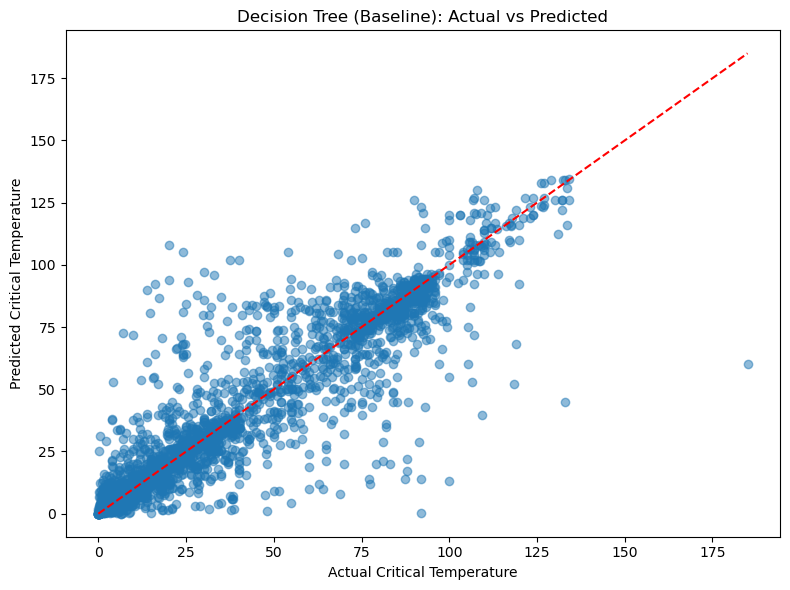

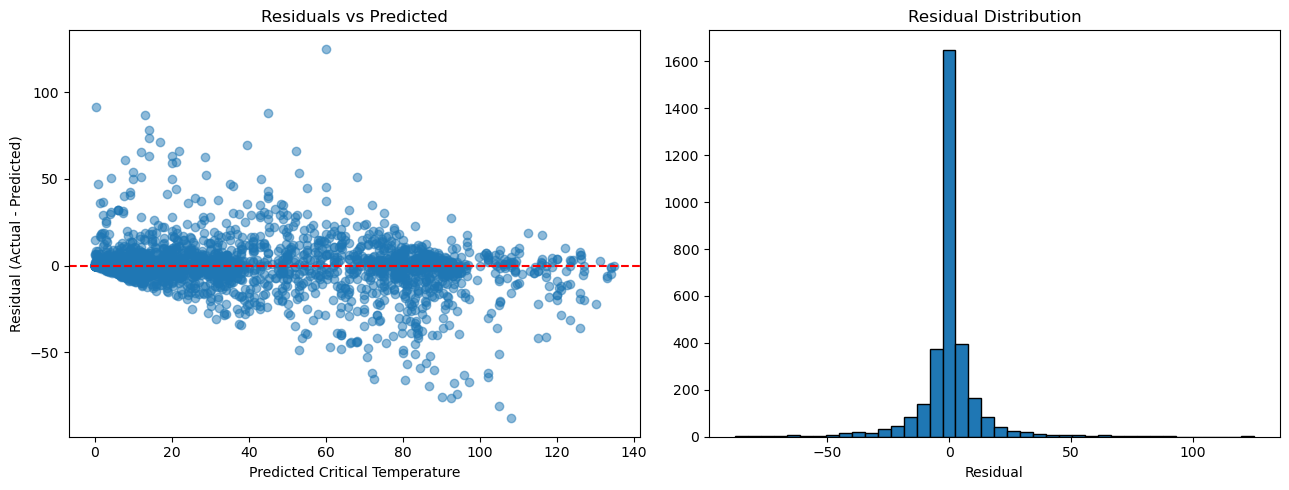

In [6]:
# Actual vs Predicted
plt.figure(figsize=(8, 6))
plt.scatter(y_test, test_pred, alpha=0.5)
lo, hi = min(y_test.min(), test_pred.min()), max(y_test.max(), test_pred.max())
plt.plot([lo, hi], [lo, hi], "r--")
plt.xlabel("Actual Critical Temperature")
plt.ylabel("Predicted Critical Temperature")
plt.title("Decision Tree (Baseline): Actual vs Predicted")
plt.tight_layout()
plt.savefig("DT_Actual_vs_Predicted.png", dpi=300)
plt.show()

# Residuals
residuals = y_test.to_numpy() - test_pred
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].scatter(test_pred, residuals, alpha=0.5)
ax[0].axhline(0, color="r", linestyle="--")
ax[0].set_xlabel("Predicted Critical Temperature")
ax[0].set_ylabel("Residual (Actual - Predicted)")
ax[0].set_title("Residuals vs Predicted")
ax[1].hist(residuals, bins=40, edgecolor="black")
ax[1].set_xlabel("Residual")
ax[1].set_title("Residual Distribution")
plt.tight_layout()
plt.savefig("DT_Residuals.png", dpi=300)
plt.show()